**Aim:** Differential Expression (DE) analysis comparing cells from different conditions (i.e. MDMA, Meth, Saline).
**Tools**
- `limma` – gene level 
- `iPAGE` – pathway level

# Differential analysis 

> Many methods have been used to determine differential gene expression from single-cell RNA (scRNA)-seq data. 

> Prefiltering of lowly expressed genes has important effects, particularly for some of the methods developed for bulk RNA-seq data analysis. However, we found that bulk RNA-seq analysis methods do not generally perform worse than those developed specifically for scRNA-seq. 

Source: [Soneson, C., Robinson, M. Bias, **robustness and scalability in single-cell differential expression analysis.** Nat Methods 15, 255–261 (2018).](https://doi.org/10.1038/nmeth.4612)

Also see 
[Wang, T., Li, B., Nelson, C.E. et al. **Comparative analysis of differential gene expression analysis tools for single-cell RNA sequencing data.** BMC Bioinformatics 20, 40 (2019).](https://doi.org/10.1186/s12859-019-2599-6)


[course chapter 12: Differential Expression (DE) analysis](https://biocellgen-public.svi.edu.au/mig_2019_scrnaseq-workshop/public/dechapter.html)


I'm also discussing this topic here https://github.com/abearab/sc-haircut-net/issues/3#issuecomment-832263091

> ### Estimate dispersion and DE using `DESeq2`
> Van den Berge and Perraudeau and others have shown the LRT may perform better for null hypothesis testing, so we use the LRT. In order to use the Wald test, it is recommended to set `useT=TRUE`.

> ### Plot dispersion estimates
> It is recommended to plot the dispersion estimates for DESeq2 on single-cell data. As discussed in the DESeq2 paper, it becomes difficult to accurately estimate the dispersion when the counts are very small, because the Poisson component of the variance is dominant. Therefore we see some very low dispersion estimates here, although the trend is still accurately capturing the upper proportion. So here everything looks good.


> If the parametric trend fails to fit (there would be a warning in this case), one should check the dispersion plot as above. If it looks like the dispersion fit is being thrown off by the low count genes with low dispersion estimates at the bottom of the plot, there is a relatively easy solution: one can filter out more of the low count genes only for the dispersion estimation step, so that the trend still captures the upper portion. This is pretty easy to do in DESeq2, to filter genes solely for the dispersion trend estimation, but to use a larger set for the rest of the analysis. An example of how this can be done:


In [1]:
import pandas as pd 
import scanpy as sc

In [2]:
def prep_diffexp_input(adata,name):
    counts = pd.DataFrame(
        adata.layers["counts"].T,
        columns = adata.obs.index.tolist(),
        index = adata.var.index.tolist()
    )

    meta = adata.obs[['batch','group']].copy()

    meta['treat'] = meta.batch.str.contains('acute').replace({True:'acute',False:'not-acute'})
    meta['rep'] = meta.batch.str[-1]

    counts.to_csv(f'diffexp/{name}_counts.txt',  sep='\t')
    meta.to_csv(f'diffexp/{name}_meta.txt',sep='\t')

In [4]:
ls celltyping/*h5ad.gz

celltyping/adata_neuron-clustered.h5ad.gz
celltyping/adata_non_neuron-clustered-labeled.h5ad.gz


In [5]:
results_file = 'celltyping/adata_neuron-clustered.h5ad.gz'

adata_neuron = sc.read_h5ad(results_file)

In [ ]:
results_file = 'celltyping/adata_non_neuron-clustered-labeled.h5ad.gz'

adata_non_neuron = sc.read_h5ad(results_file)

In [8]:
set(adata_non_neuron.obs.label)

{'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'}

## Prep inputs

In [6]:
prep_diffexp_input(adata_neuron,'all_neurons')

### Astrocytes

In [9]:
Astrocytes = adata_non_neuron[adata_non_neuron.obs.label == 'Astrocytes'].copy()

In [10]:
prep_diffexp_input(Astrocytes,'Astrocytes')

### Microglia

In [11]:
Microglia = adata_non_neuron[adata_non_neuron.obs.label == 'Microglia'].copy()

In [12]:
prep_diffexp_input(Microglia,'Microglia')

### Endothelial


In [13]:
Endothelial = adata_non_neuron[adata_non_neuron.obs.label == 'Endothelial'].copy()

In [14]:
prep_diffexp_input(Endothelial,'Endothelial')

### Oligodendrocytes

In [15]:
Oligodendrocytes = adata_non_neuron[adata_non_neuron.obs.label == 'Oligodendrocytes'].copy()

In [16]:
prep_diffexp_input(Oligodendrocytes,'Oligodendrocytes')

## Run DE

___

`deseq` env

In [3]:
!Rscript diffexp.R all_neurons

### Astrocytes

In [4]:
!Rscript diffexp.R Astrocytes

### Microglia

In [5]:
!Rscript diffexp.R Microglia

### Endothelial


In [6]:
!Rscript diffexp.R Endothelial

### Oligodendrocytes

In [2]:
!Rscript diffexp.R Oligodendrocytes

## Explore DE results

___

`deseq` R env

In [3]:
source('plots.R')

draw_volcano <- function(name,xlim=10,lfc.cutoff = 1, pval.cutoff = 0.05){
    read.table(paste0('diffexp/',name,'/delta_exp_MDMAvsSaline.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle(paste0(name,'\nMDMAvsSaline'))  -> p1

    read.table(paste0('diffexp/',name,'/delta_exp_MDMAvsMeth.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle('MDMAvsMeth')  -> p2

    read.table(paste0('diffexp/',name,'/delta_exp_MethvsSaline.txt')) %>% 
        plot_Volcano (x_min=-xlim,x_max=xlim,lfc.cutoff = lfc.cutoff, pval.cutoff = pval.cutoff ) +
        ggtitle('MethvsSaline')  -> p3

    return(p1 / p2/ p3)
}

In [ ]:
draw_volcano('all_neurons',xlim=5,lfc.cutoff=0.5)

### Astrocytes

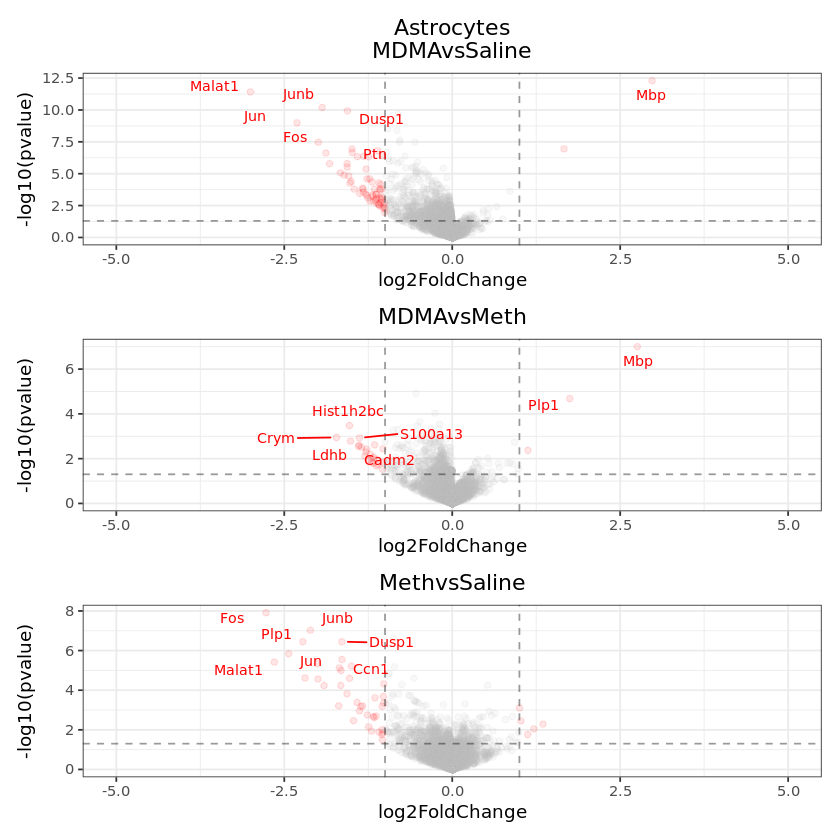

In [5]:
draw_volcano('Astrocytes',5)

### Microglia

Warning message:
“ggrepel: 3 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


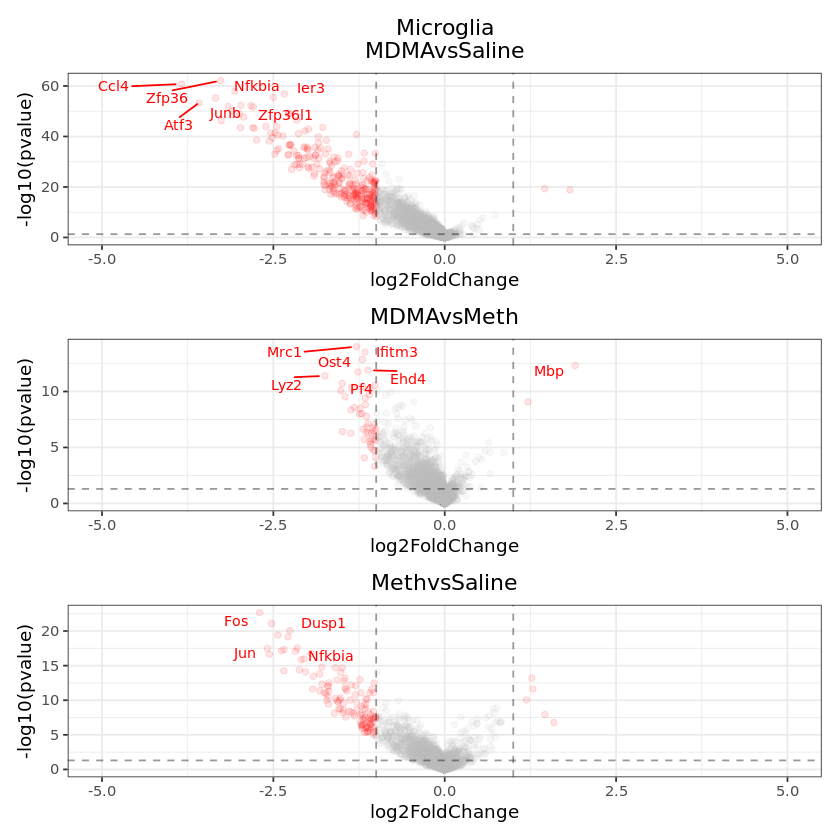

In [6]:
draw_volcano('Microglia',5)

### Endothelial


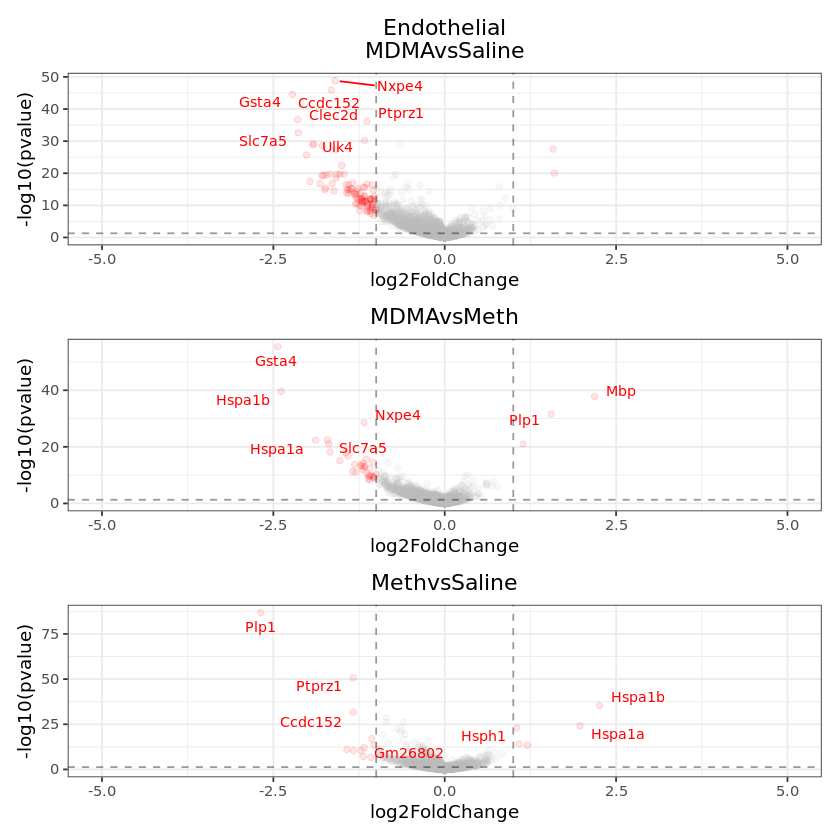

In [7]:
draw_volcano('Endothelial',5)

### Oligodendrocytes

Warning message:
“ggrepel: 4 unlabeled data points (too many overlaps). Consider increasing max.overlaps”
Warning message:
“ggrepel: 2 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


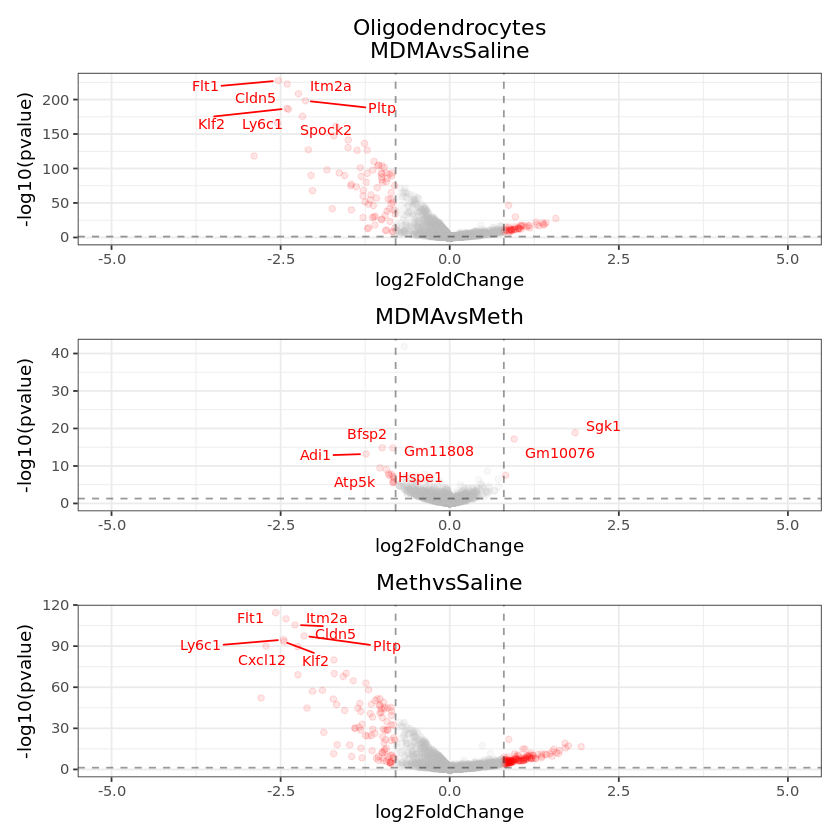

In [8]:
draw_volcano('Oligodendrocytes',xlim=5,lfc.cutoff=0.8)

## Pathway analysis

### GSEA

In [2]:
import pandas as pd 
# from utils import *

from matplotlib import pyplot as plt
from venn import venn 

In [3]:
import blitzgsea as blitz

In [4]:
def read_diffexp_table(name):
    d = {
        'MethvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MethvsSaline.txt',  sep='\t'),
        'MDMAvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsSaline.txt',sep='\t'),
        'MDMAvsMeth':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsMeth.txt',  sep='\t')
    }

    out = pd.concat(d.values(), axis=1, keys=d.keys())
    out.index = out.index.str.upper()
    return out

In [5]:
m5_gmt = blitz.enrichr.read_gmt(
    '/data_gilbert/home/aarab/Projects/pager/annotations/mouse/m5.all.v2022.1.Mm.symbols.gmt'
)

In [6]:
m8_gmt = blitz.enrichr.read_gmt(
    '/data_gilbert/home/aarab/Projects/pager/annotations/mouse/m8.all.v2022.1.Mm.symbols.gmt'
)

___

In [9]:
GSEA_res = {}

for cond in ['all_neurons',
             'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    GSEA_res[cond] = {}
    for comp in ['MDMAvsMeth','MDMAvsSaline','MethvsSaline']:
        signature = read_diffexp_table(cond)[comp]['log2FoldChange'].reset_index()
        result = blitz.gsea(signature,m5_gmt,min_size=5,verbose=True)
        
        GSEA_res[cond][comp] = {
            'signature':signature,
            'result':result,
        }

Enrichment : 100%|██████████| 10652/10652 [00:09<00:00, 1115.93it/s]


In [10]:
for cond in ['all_neurons',
             'Astrocytes', 'Endothelial', 
             'Microglia', 'Oligodendrocytes'
            ]:
    
    writer = pd.ExcelWriter(f'diffexp/DEG_{cond}.xlsx', engine='xlsxwriter')
    read_diffexp_table(cond).to_excel(writer, sheet_name='comparisons')

    for comp in ['MDMAvsMeth','MDMAvsSaline','MethvsSaline']:
        GSEA_res[cond][comp]['result'].to_excel(writer, sheet_name=comp)
    writer.save()

In [ ]:
GSEA_res.keys()

In [ ]:
signature = GSEA_res['Oligodendrocytes']['MDMAvsMeth']['signature'].copy()
gsea_result = GSEA_res['Oligodendrocytes']['MDMAvsMeth']['result'].copy()

fig_table = blitz.plot.top_table(
    signature,m5_gmt,
    gsea_result[
        ((gsea_result.index.str.contains('NEURO')) | 
        (gsea_result.index.str.contains('BRAIN'))) & 
        (gsea_result.geneset_size < 50)
         ]
)
# fig_table.savefig("gsea_top_nes_pos_table.pdf", bbox_inches='tight')
fig_table

### 

In [ ]:
# %%bash
# zip -r diffexp/Astrocytes_DE.zip diffexp/Astrocytes_delta_exp_* 

# zip -r diffexp/Microglia_DE.zip diffexp/Microglia_delta_exp_* 

#

In [13]:
!date

Wed Aug 10 21:31:32 PDT 2022
